# 📘 11.2 Applying Boundary Conditions to PDEs
###

This notebook focuses on the theory and numerical implementation of the four fundamental boundary conditions used in solving Partial Differential Equations (PDEs):

*   **Dirichlet Boundary Conditions** (fixed values at the boundaries)
*   **Neumann Boundary Conditions** (fixed derivative or flux at the boundaries, implemented using ghost points)
*   **Robin Boundary Conditions** (mixed value and derivative/flux conditions)
*   **Periodic Boundary Conditions** (continuous wrap-around boundaries)

We will explore how these conditions are formulated mathematically, how they are translated into Finite Difference schemes (both explicit and implicit), and observe their physical impact on 1-D diffusion simulations over short and long time scales.

### 🎯 Learning Objectives
> By the end of this notebook, you should be able to:
>
> * **Understand** the mathematical definition and physical meaning of the four fundamental boundary condition types: Dirichlet, Neumann, Robin, and Periodic.
> * **Apply** these boundary conditions to discretised Partial Differential Equations (PDEs) using Finite Difference schemes, including the use of ghost points for gradient-based conditions.
> * **Analyze** how different boundary conditions influence the physical behavior and long-term numerical solution of a simulated system.

## 📂 11.2.0 How to use this notebook

This notebook builds directly on the finite difference representations of spatial and temporal derivatives we established in previous sections. Rather than simulating systems with simplified boundaries, we now look at how to model real-world physics by implementing conditions that go beyond simply setting a fixed value at the edge of our domain.

In computational engineering fields such as **Computational Fluid Dynamics (CFD)**, **Finite Element Analysis (FEA)**, and other multiphysics codes, specifying what happens at the borders of your physical domain is critical to obtaining physically realistic, stable, and unique solutions. In this notebook, we will formally introduce the terminology of different boundary condition (BC) types, and learn how they are represented in finite difference stencils.

It is important that you are familiar with the terminology around these BCs and understand how to implement them in discretised PDEs.

## 📂 11.2.1 Boundary Conditions

---

In section 10.1.1, we mentioned the need for both the initial condition $\phi(t^n=0,x_j)$ from which the solution will march forward in time, and the boundary conditions at $x_0$ and $x_{N-1}$. We cannot apply a spatial centred difference at these points as there is no point at $j<0$ and no point at $j > N-1$. How we handle these points depends on the nature of the boundary conditions that represent the physical problem.

There are four **fundamental numerical boundary condition types**.

### 🔹 Dirichlet (fixed value)
> ### 📖 Definition
> **Dirichlet** Boundary Condition:
> $$\phi = g$$
> The value of the solution is defined at the boundary, e.g. fixed temperature, fixed displacement, fixed velocity, ...

When it comes to **explicit** *Finite Difference* methods, this can be applied by directly overwriting the values of boundary nodes, e.g.
$$\phi^n_{j=0} = g_{left},\qquad \phi^n_{j=N-1} = g_{right}.$$

For **implicit** schemes, this will generally require the first row of the matrix representing
$$\phi^n_{j=0} = g_{left},$$
and the last row
$$\phi^n_{j=N-1} = g_{right},$$
such that the BCs are enforced by the solution of the matrix.

### 🔹 Neumann (fixed derivative / flux)
>>### 📖 Definition
> **Neumann** Boundary Condition:
> $$\frac{\partial \phi}{\partial x}= h$$
> The value of the gradient is defined at the boundary, e.g. insulated wall (zero flux $\partial T/\partial x = 0$), specified heat flux, free end of a vibrating string.

In *Finite Difference* methods, this is often implemented via the use of *ghost points*, i.e. adding a value for a point at $j=-1$ which can be used in a centred difference stencil around $j=0$ like

$$ \frac{\partial \phi^n_0}{\partial x} = \frac{\phi^n_{1}-\phi^n_{-1}}{2\Delta x} + \mathcal{O}(\Delta x^2).$$

The value $\phi^n_{-1}$ is not evaluated like the internal nodes, but can be set to ensure the desired gradient, since $h$ at $j=0$ the gradient at the boundary point becomes

$$\frac{\partial \phi^n_0}{\partial x} = \frac{\phi^n_{1}-\phi^n_{-1}}{2\Delta x} = h$$

which can be achieved by setting the value at the ghost point as

$$\phi^n_{-1} = \phi^n_1 - 2h\Delta_x.$$

As the value of $\phi^n_0$ at the boundary is not set (the gradient is), we need to solve for $\phi^n_0$. This is done by including the boundary point in the PDE calculation.

For example, in the case of the application of the **Forward Time, Centre Space** method to the diffusion equation from Notebook 11.1, the following discretised form of the PDE,

$$\phi^{n+1}_j = \phi^n_j+\frac{D\Delta t}{\Delta x^2}\left(\phi^n_{j-1}-2\phi^n_j + \phi^n_{j+1}\right),$$

has to be solved for $j=0$. This is done by substituting in the value for the *ghost point*, needed to satisfy the gradient, i.e.

\begin{align}
\phi^{n+1}_0 &= \phi^n_0+\frac{D\Delta t}{\Delta x^2}\left(\phi^n_{-1}-2\phi^n_0 + \phi^n_{1}\right)\\
&=\phi^n_0+\frac{D\Delta t}{\Delta x^2}\left(\phi^n_1 - 2h\Delta_x-2\phi^n_0 + \phi^n_{1}\right)\\
&=\phi^n_0+2\frac{D\Delta t}{\Delta x^2}\left(\phi^n_1 - h\Delta_x-\phi^n_0\right).
\end{align}

The PDE at the boundary point now includes the gradient boundary conditions, updating the value of $\phi$ at the boundary in order to ensure both the PDE and BC are satisfied.

**Why did we use this,**

$$ \frac{\partial \phi^n_0}{\partial x} = \frac{\phi^n_{1}-\phi^n_{-1}}{2\Delta x} + \mathcal{O}(\Delta x^2),$$

**form of the gradient and not a forward difference?**
This version of the gradient was chosen to ensure the *second-order* accuracy of the centred difference was maintained. A *forward difference* is only first-order accurate and would reduce the accuracy of the entire solution.

### 🔹 Robin (mixed value and derivative / flux)
>>### 📖 Definition
> **Robin** Boundary Condition:
> $$\alpha \phi + \beta\frac{\partial \phi}{\partial x}= g$$
> A linear combination of the value of a function and the value of its derivative at the boundary of a given domain.
>
> A common physical example is heat transfer, where a surface might lose heat to the environment via convection. In such cases the heat transfer by convection is balanced by the conduction through the surface,
$$ h(T_w-T_\infty) = -k\frac{\partial T}{\partial n},$$
where $h$ is the heat transfer coefficient, $T_w$ is the wall temperature, $k$ the thermal conductivity and $n$ the direction normal to the wall. If we know the ambient temperature then we can express this as
$$hT_w+k\frac{\partial T}{\partial n}= hT_\infty,$$
via a Robin BC, where the solution needs to solve for both the unknown temperature and unknown gradient at the wall.

As with the Neumann BC, this can be implemented in a *Finite Difference* Scheme, via the use of a **ghost point**. Replacing the gradient in the boundary conditions with

$$ \frac{\partial \phi^n_0}{\partial x} = \frac{\phi^n_{1}-\phi^n_{-1}}{2\Delta x} + \mathcal{O}(\Delta x^2),$$

which when substituted into the boundary condition yields

\begin{align}
\alpha \phi^n_0 + \beta\frac{\partial \phi^n_0}{\partial x}&= g\\
\alpha \phi^n_0 + \beta\frac{\phi^n_{1}-\phi^n_{-1}}{2\Delta x}&= g.
\end{align}

This can be rearranged to give the following value for the *ghost point*

$$\phi^n_{-1} = \phi^n_1+\frac{2\Delta x}{\beta}\left(\alpha\phi^n_0-g\right),$$

which can be *substituted* into the PDEs to enable the calculation of the field at the boundary which satisfies this combined value and gradient BC.

### 🔹 Periodic
>>### 📖 Definition
> **Periodic** Boundary Condition:
> $$\phi^n_0 = \phi^n_{N-1}, \qquad \frac{\partial \phi^n_0}{\partial x} = \frac{\partial \phi^n_{N-1}}{\partial x}$$
> A continuous periodic extension of the domain, where leaving one side brings you back into the other.
>
> This is common in many canonical fluid flows where the domain is assumed to be infinitely large in one or more dimensions such that the solution can develop unconstrained. This is like assuming that the region of the solution you are concerned with is far enough away that you do not need to model the impact of side walls. This also applies to pipes and similar domains where the edges of the domain meet and the solution must be consistent.

In *Finite Differences* this is implemented by adding *ghost points* to both periodic sides of the domain, e.g. $\phi_{-1}$ and $\phi_N$, where the $N$ points across the domain range from $j=0\to N-1$. As with the Neumann method, the values at $j=0$ and $j=N-1$ need to be determined from the PDE solution, which will require values from $j=-1$ and $j=N$, respectively.

To ensure the flow is periodic, these values come from the opposite side of the solution domain, i.e.

$$\phi^n_{-1} = \phi^n_{N-1}, \qquad \phi^n_{N} = \phi^n_0.$$

These values are then used in the spatial Finite Difference stencils to ensure the solution circulates back to the opposite side of the domain.

## 📂 11.2.3 Numerical Examples

---

Consider the 1-D diffusion equation from Notebook 11.1

$$ \frac{\partial \phi}{\partial t} = D\,\frac{\partial^2 \phi}{\partial x^2}
$$

implemented with Dirichlet, Neumann, Robin, and Periodic boundary conditions.

Examples below all use the explicit **Forward Time, Centred Space** scheme, which is relatively easy to read, and structured so you can swap BCs cleanly.

The code below includes four separate functions that have been used to apply the different boundary conditions. In all cases, they are applied after evaluating the PDE to determine the temporal update of all the internal nodes.

The example cases below are as follows:
* In the case of the **Dirichlet** BC, both ends of the domain have been set to a constant value $\phi_0 = \phi_{N-1} = 0$.
* For the **Neumann** example, both sides of the domain have a set weak positive gradient on each end of the domain to better separate the results from other conditions.
* For **Robin** conditions, this is applied at the left-hand side with a set $\phi_{N-1}=0$ applied to the right-hand side. In this case, we have set the condition so $\phi$ is convecting into the left-hand side of the domain.
* The **Periodic** case is just that. Any $\phi$ that might flow out of one side comes back into the other.

We have set all examples to run from the same initial condition for 500 steps.

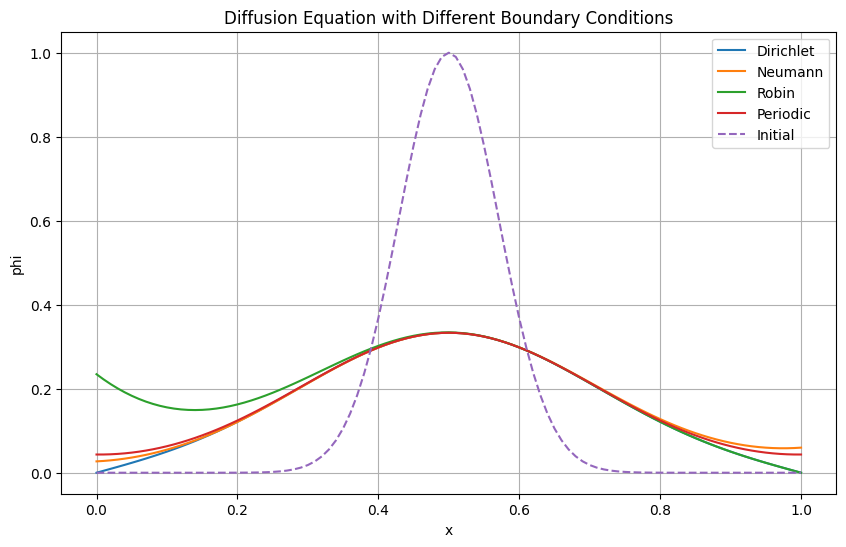

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Core PDE parameters
# ------------------------------------------------------------
D = 1.0          # diffusion coefficient
L = 1.0          # domain length
Nx = 101         # number of grid points
dx = L / (Nx - 1)
dt = 0.4 * dx**2 / D   # stable FTCS time step (r <= 1/2)
r = D * dt / dx**2

x = np.linspace(0, L, Nx)

# Initial condition: Gaussian bump
phi0 = np.exp(-100 * (x - 0.5)**2)

# ------------------------------------------------------------
# Boundary condition handlers
# ------------------------------------------------------------

def apply_dirichlet(phi, left_val=0.0, right_val=0.0):
    phi[0] = left_val
    phi[-1] = right_val
    return phi

def apply_neumann(phi, left_flux=0.0, right_flux=0.0):
    # dphi/dx = flux
    # ghost nodes:
    # phi[-1] = phi[1] - 2*flux*dx
    phi_left_ghost  = phi[1] - 2 * left_flux * dx
    phi_right_ghost = phi[-2] + 2 * right_flux * dx

    # update boundary using ghost nodes
    phi[0] = phi[0] + r * (phi[1] - 2*phi[0] + phi_left_ghost)
    phi[-1] = phi[-1] + r * (phi_right_ghost - 2*phi[-1] + phi[-2])
    return phi

def apply_robin(phi, alpha, beta, g):
    # alpha*phi + beta*dphi/dx = g
    # ghost: phi[-1] = phi[1] - (2*dx/beta)*(g - alpha*phi[0])
    phi_left_ghost = phi[1] - (2*dx/beta)*(g - alpha*phi[0])
    phi[0] = phi[0] + r * (phi[1] - 2*phi[0] + phi_left_ghost)
    return phi

def apply_periodic(phi):
    # wrap-around ghost nodes
    left_ghost  = phi[-2]   # phi[-1] = phi[N-1]
    right_ghost = phi[1]    # phi[N] = phi[0]
    phi_new = phi.copy()
    phi_new[0] = phi[0] + r * (phi[1] - 2*phi[0] + left_ghost)
    phi_new[-1] = phi[-1] + r * (right_ghost - 2*phi[-1] + phi[-2])
    return phi_new

# ------------------------------------------------------------
# Time stepping function
# ------------------------------------------------------------

def diffuse(phi, steps, bc_type="dirichlet"):
    phi = phi.copy()
    for _ in range(steps):
        phi_new = phi.copy()

        # interior update
        phi_new[1:-1] = phi[1:-1] + r * (phi[2:] - 2*phi[1:-1] + phi[:-2])

        # apply boundary condition
        if bc_type == "dirichlet":
            phi_new = apply_dirichlet(phi_new, left_val=0.0, right_val=0.0)

        elif bc_type == "neumann":
            phi_new = apply_neumann(phi_new, left_flux=0.1, right_flux=0.1)

        elif bc_type == "robin":
            phi_new = apply_robin(phi_new, alpha=1.0, beta=1.0, g=-1.0)

        elif bc_type == "periodic":
            phi_new = apply_periodic(phi_new)

        phi = phi_new

    return phi

# ------------------------------------------------------------
# Run examples
# ------------------------------------------------------------
phi_dirichlet = diffuse(phi0, steps=500, bc_type="dirichlet")
phi_neumann   = diffuse(phi0, steps=500, bc_type="neumann")
phi_robin     = diffuse(phi0, steps=500, bc_type="robin")
phi_periodic  = diffuse(phi0, steps=500, bc_type="periodic")

# ------------------------------------------------------------
# Plot results
# ------------------------------------------------------------
plt.figure(figsize=(10,6))
plt.plot(x, phi_dirichlet, label="Dirichlet")
plt.plot(x, phi_neumann, label="Neumann")
plt.plot(x, phi_robin, label="Robin")
plt.plot(x, phi_periodic, label="Periodic")
plt.plot(x, phi0, '--', label="Initial")
plt.legend()
plt.xlabel("x")
plt.ylabel("phi")
plt.title("Diffusion Equation with Different Boundary Conditions")
plt.grid(True)
plt.show()


If we run this for longer, we can see how these BC continue to impact the solution.

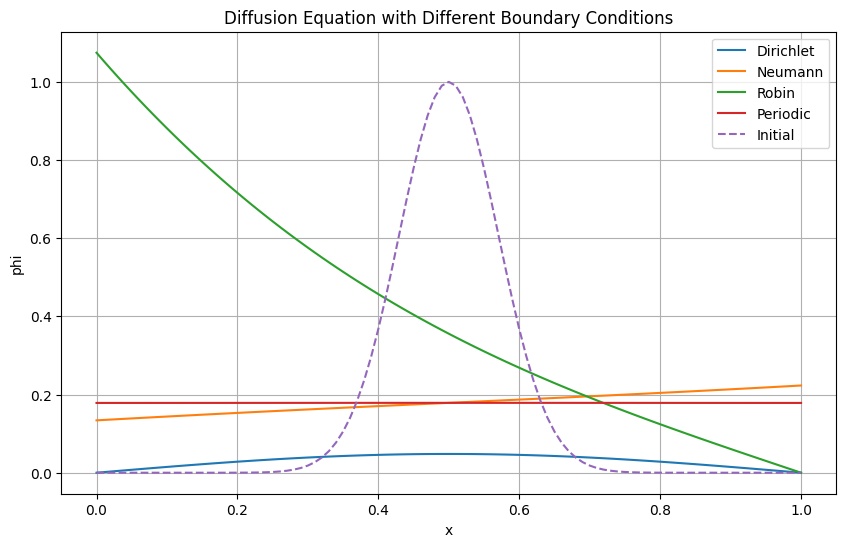

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Core PDE parameters
# ------------------------------------------------------------
D = 1.0          # diffusion coefficient
L = 1.0          # domain length
Nx = 101         # number of grid points
dx = L / (Nx - 1)
dt = 0.4 * dx**2 / D   # stable FTCS time step (r <= 1/2)
r = D * dt / dx**2

x = np.linspace(0, L, Nx)

# Initial condition: Gaussian bump
phi0 = np.exp(-100 * (x - 0.5)**2)

# ------------------------------------------------------------
# Boundary condition handlers
# ------------------------------------------------------------

def apply_dirichlet(phi, left_val=0.0, right_val=0.0):
    phi[0] = left_val
    phi[-1] = right_val
    return phi

def apply_neumann(phi, left_flux=0.0, right_flux=0.0):
    # dphi/dx = flux
    # ghost nodes:
    # phi[-1] = phi[1] - 2*flux*dx
    phi_left_ghost  = phi[1] - 2 * left_flux * dx
    phi_right_ghost = phi[-2] + 2 * right_flux * dx

    # update boundary using ghost nodes
    phi[0] = phi[0] + r * (phi[1] - 2*phi[0] + phi_left_ghost)
    phi[-1] = phi[-1] + r * (phi_right_ghost - 2*phi[-1] + phi[-2])
    return phi

def apply_robin(phi, alpha, beta, g):
    # alpha*phi + beta*dphi/dx = g
    # ghost: phi[-1] = phi[1] - (2*dx/beta)*(g - alpha*phi[0])
    phi_left_ghost = phi[1] - (2*dx/beta)*(g - alpha*phi[0])
    phi[0] = phi[0] + r * (phi[1] - 2*phi[0] + phi_left_ghost)
    return phi

def apply_periodic(phi):
    # wrap-around ghost nodes
    left_ghost  = phi[-2]   # phi[-1] = phi[N-1]
    right_ghost = phi[1]    # phi[N] = phi[0]
    phi_new = phi.copy()
    phi_new[0] = phi[0] + r * (phi[1] - 2*phi[0] + left_ghost)
    phi_new[-1] = phi[-1] + r * (right_ghost - 2*phi[-1] + phi[-2])
    return phi_new

# ------------------------------------------------------------
# Time stepping function
# ------------------------------------------------------------

def diffuse(phi, steps, bc_type="dirichlet"):
    phi = phi.copy()
    for _ in range(steps):
        phi_new = phi.copy()

        # interior update
        phi_new[1:-1] = phi[1:-1] + r * (phi[2:] - 2*phi[1:-1] + phi[:-2])

        # apply boundary condition
        if bc_type == "dirichlet":
            phi_new = apply_dirichlet(phi_new, left_val=0.0, right_val=0.0)

        elif bc_type == "neumann":
            phi_new = apply_neumann(phi_new, left_flux=0.1, right_flux=0.1)

        elif bc_type == "robin":
            phi_new = apply_robin(phi_new, alpha=1.0, beta=1.0, g=-1.0)

        elif bc_type == "periodic":
            phi_new = apply_periodic(phi_new)

        phi = phi_new

    return phi

# ------------------------------------------------------------
# Run examples
# ------------------------------------------------------------
phi_dirichlet = diffuse(phi0, steps=5000, bc_type="dirichlet")
phi_neumann   = diffuse(phi0, steps=5000, bc_type="neumann")
phi_robin     = diffuse(phi0, steps=5000, bc_type="robin")
phi_periodic  = diffuse(phi0, steps=5000, bc_type="periodic")

# ------------------------------------------------------------
# Plot results
# ------------------------------------------------------------
plt.figure(figsize=(10,6))
plt.plot(x, phi_dirichlet, label="Dirichlet")
plt.plot(x, phi_neumann, label="Neumann")
plt.plot(x, phi_robin, label="Robin")
plt.plot(x, phi_periodic, label="Periodic")
plt.plot(x, phi0, '--', label="Initial")
plt.legend()
plt.xlabel("x")
plt.ylabel("phi")
plt.title("Diffusion Equation with Different Boundary Conditions")
plt.grid(True)
plt.show()


After 5000 steps, the **Dirichlet** case allows $\phi$ to continue to be transported out of the domain, unlike the **Neumann** condition, which has set the rates that enter and leave on either side.

As we set the **Robin** condition to have $\phi$ convecting in via the left-hand side and forcing zero on the right, we can see that this BC has now taken over from the initial Gaussian.

The **periodic** case in this example is unique, as it is the only condition that prevents $\phi$ from leaving the domain. This has resulted in $\phi$ diffusing evenly across the domain.

You can represent all sorts of physical phenomena through combinations of these boundary conditions. The principles discussed here can be extended to multiple dimensions.

## 🔗 Bridge to Next Sections

In this notebook, we extended the parabolic FTCS solver introduced in **Notebook 11.1** by implementing more advanced, physically realistic boundary conditions. Rather than relying solely on simple, fixed boundary values, we learned how to discretize and apply:
* **Dirichlet** (fixed values)
* **Neumann** (specified derivatives/fluxes using ghost points)
* **Robin** (mixed value and gradient conditions)
* **Periodic** (wrap-around domain mapping)

We simulated and compared how these conditions dictate the long-term behavior and equilibrium states of a 1-D diffusion system.

In **Notebook 11.3** will transition from time-dependent parabolic equations to **Elliptical PDEs** (such as Laplace and Poisson equations) where we will explore steady-state solvers and boundary value problems.

# 🤖 AI Acknowledgment

Google Gemini was used to proofread this document. MS CoPilot v25.6.440430001 was used to generate the sample FTCS code used as the basis for the implementation of different boundary conditions and their influence on the diffusion equation.